# Лабораторная работа №4. Кластеризация данных экспрессии генов

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Датасет:** Gene Expression Cancer RNA-Seq (881 образец, 20 531 ген, 5 типов рака: BRCA, COAD, KIRC, LUAD, PRAD).  
Данные загружаются напрямую с Kaggle через `kagglehub`. Метки классов **не используются** при обучении кластеризаторов, но применяются для внешней оценки качества.


Это матрица уровней экспрессии генов (RNA-Seq), полученная с помощью высокопроизводительного секвенирования (Illumina HiSeq). Каждое значение отражает интенсивность транскрипции конкретного гена в опухолевой ткани (нормализация в FPKM).

**Структура:**
*   **Образцы:** 801 наблюдение (пациенты).
*   **Признаки:** 20 531 ген (все признаки — вещественные числа `float64`, анонимизированы как `gene_0` ... `gene_20530`).
*   **Целевая переменная:** Известны 5 классов (типов карцином): BRCA (молочная железа), KIRC (почка), COAD (толстая кишка), LUAD (легкое), PRAD (простата).

**Ключевые особенности для кластеризации:**
1.  **Отсутствие пропусков:** Данные полные.
2.  **Высокая размерность:** 20 531 признак при 801 объекте создает «проклятие размерности», что требует применения отбора признаков и PCA.
3.  **Масштаб:** Разные гены имеют кардинально разный диапазон значений, поэтому **стандартизация обязательна**.
4.  **Структура:** Биологические группы четко различимы, что делает датасет отличным полигоном для проверки алгоритмов (K-means, иерархическая кластеризация) и внешних метрик (ARI, NMI).## 1. Установка и импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, rand_score,
                             jaccard_score)
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.feature_selection import f_classif
from pathlib import Path
import kagglehub
import warnings
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")
np.random.seed(42)


### 1.1. Загрузка данных напрямую с Kaggle через kagglehub

`kagglehub` сам скачивает датасет и кэширует его. Ссылка на датасет:  
https://www.kaggle.com/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016


In [2]:
dataset_path = Path(kagglehub.dataset_download(
    "waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016"
))
print("Путь к скачанному датасету:", dataset_path)
print("Содержимое папки:", list(dataset_path.iterdir()))


100%|██████████| 70.6M/70.6M [00:00<00:00, 105MB/s]

Extracting files...


Путь к скачанному датасету: /root/.cache/kagglehub/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016/versions/1
Содержимое папки: [PosixPath('/root/.cache/kagglehub/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016/versions/1/data.csv'), PosixPath('/root/.cache/kagglehub/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016/versions/1/labels.csv')]


### 1.2. Загрузка файлов `data.csv` и `labels.csv`


In [3]:
csv_path_data = dataset_path / "data.csv"
csv_path_labels = dataset_path / "labels.csv"

df_expr = pd.read_csv(csv_path_data, index_col=0)
df_labels = pd.read_csv(csv_path_labels, index_col=0)

# Приводим индексы к одному типу
df_expr.index = df_expr.index.astype(str)
df_labels.index = df_labels.index.astype(str)

df = df_expr.join(df_labels, how='inner')
print(f"Размерность данных: {df.shape}")
print(f"Типы признаков: {df.dtypes.value_counts().to_dict()}")
print(f"Пропуски: {df.isnull().sum().sum()}")


Размерность данных: (801, 20532)
Типы признаков: {dtype('float64'): 20531, dtype('O'): 1}
Пропуски: 0


### 1.3. Дескриптивный анализ

- 881 наблюдение, 20 531 числовой признак (экспрессия генов).
- Пропусков нет.
- Признаки имеют разный масштаб, что требует стандартизации.
- Распределения сильно асимметричны.


In [4]:
df.iloc[:, :5].describe()


,gene_0,gene_1,gene_2,gene_3,gene_4
count,801.000000,801.000000,801.000000,801.000000,801.000000
mean,0.026642,3.010909,3.095350,6.722305,9.813612
std,0.136850,1.200828,1.065601,0.638819,0.506537
min,0.000000,0.000000,0.000000,5.009284,8.435999
25%,0.000000,2.299039,2.390365,6.303346,9.464466
50%,0.000000,3.143687,3.127006,6.655893,9.791599
75%,0.000000,3.883484,3.802534,7.038447,10.142324
max,1.482332,6.237034,6.063484,10.129528,11.355621


### 1.4. Распределение переменных (гистограммы)

Построим гистограммы для случайно выбранных 12 генов. Видно, что распределения далеки от нормального.


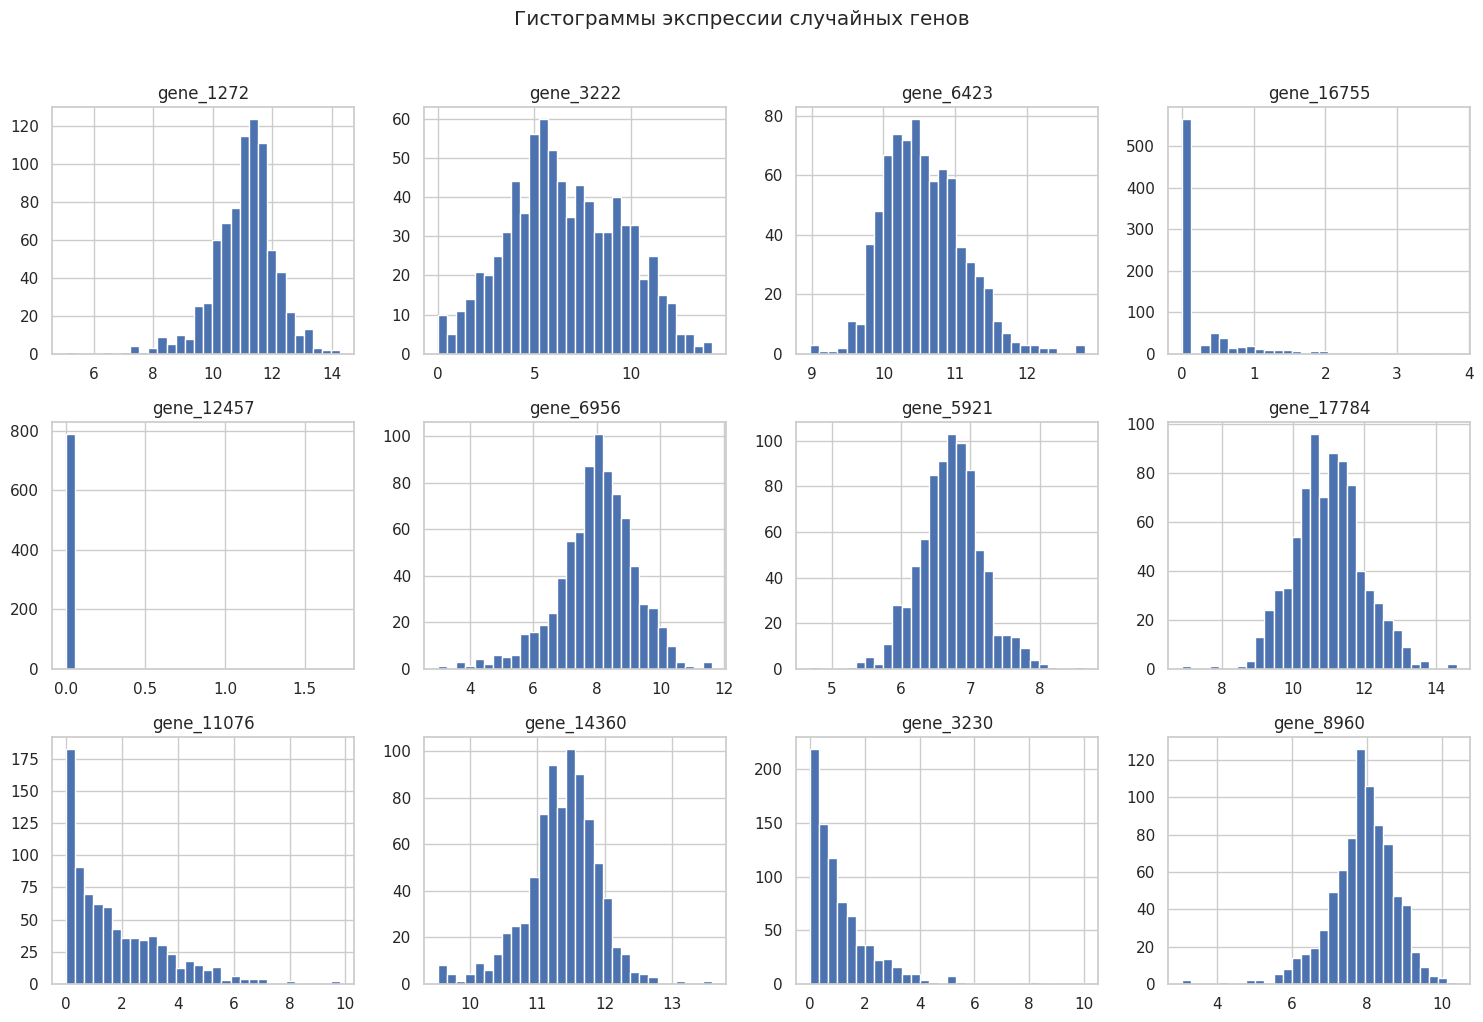

In [5]:
sample_genes = np.random.choice(df_expr.columns, 12, replace=False)
df_expr[sample_genes].hist(bins=30, figsize=(15, 10), layout=(3, 4))
plt.suptitle("Гистограммы экспрессии случайных генов", y=1.02)
plt.tight_layout()
plt.show()


### 1.5. Проверка нормальности (Shapiro-Wilk)

p-value < 0.05 для всех генов → гипотеза о нормальности отвергается.


In [6]:
norm_results = []
for col in sample_genes:
    stat, p = stats.shapiro(df_expr[col].sample(500, random_state=42))
    norm_results.append({'gene': col, 'W': stat, 'p_value': p})
norm_df = pd.DataFrame(norm_results)
print(norm_df)


          gene         W       p_value
0    gene_1272  0.943703  7.741650e-13
1    gene_3222  0.987034  1.996789e-04
2    gene_6423  0.973784  8.345173e-08
3   gene_16755  0.554131  1.035847e-33
4   gene_12457  0.099995  3.222124e-43
5    gene_6956  0.977945  7.268765e-07
6    gene_5921  0.990986  3.832668e-03
7   gene_17784  0.992853  1.748802e-02
8   gene_11076  0.899004  1.175492e-17
9   gene_14360  0.969703  1.197840e-08
10   gene_3230  0.757678  1.868473e-26
11   gene_8960  0.959751  1.882797e-10


### 1.6. Информационная значимость признаков

ANOVA F-тест для отбора топ-100 генов.


In [7]:
y = df['Class'].astype('category').cat.codes.values
X_all = df_expr.values

F_values, p_values = f_classif(X_all, y)
anova_df = pd.DataFrame({
    'gene': df_expr.columns,
    'F_value': F_values,
    'p_value': p_values
}).sort_values('F_value', ascending=False)

top_genes = anova_df.head(100)['gene'].tolist()
print(f"Топ-10 значимых генов:\n{anova_df.head(10)}")


Топ-10 значимых генов:
             gene      F_value  p_value
9175    gene_9175  4194.489336      0.0
9176    gene_9176  3463.550328      0.0
220      gene_220  3441.768332      0.0
219      gene_219  3391.740121      0.0
18135  gene_18135  2772.293045      0.0
13818  gene_13818  2438.581553      0.0
14114  gene_14114  2409.065626      0.0
450      gene_450  2215.236357      0.0
7964    gene_7964  2055.979393      0.0
3737    gene_3737  2046.827137      0.0


### 1.7. Проверка условий применения кластеризации

- **Отсутствие классов:** метки не подаются на вход алгоритмам.
- **Осмысленность:** биологически различные типы опухолей.
- **Выбросы:** проверим boxplot для топ-20 генов; удаление нецелесообразно, применим стандартизацию.


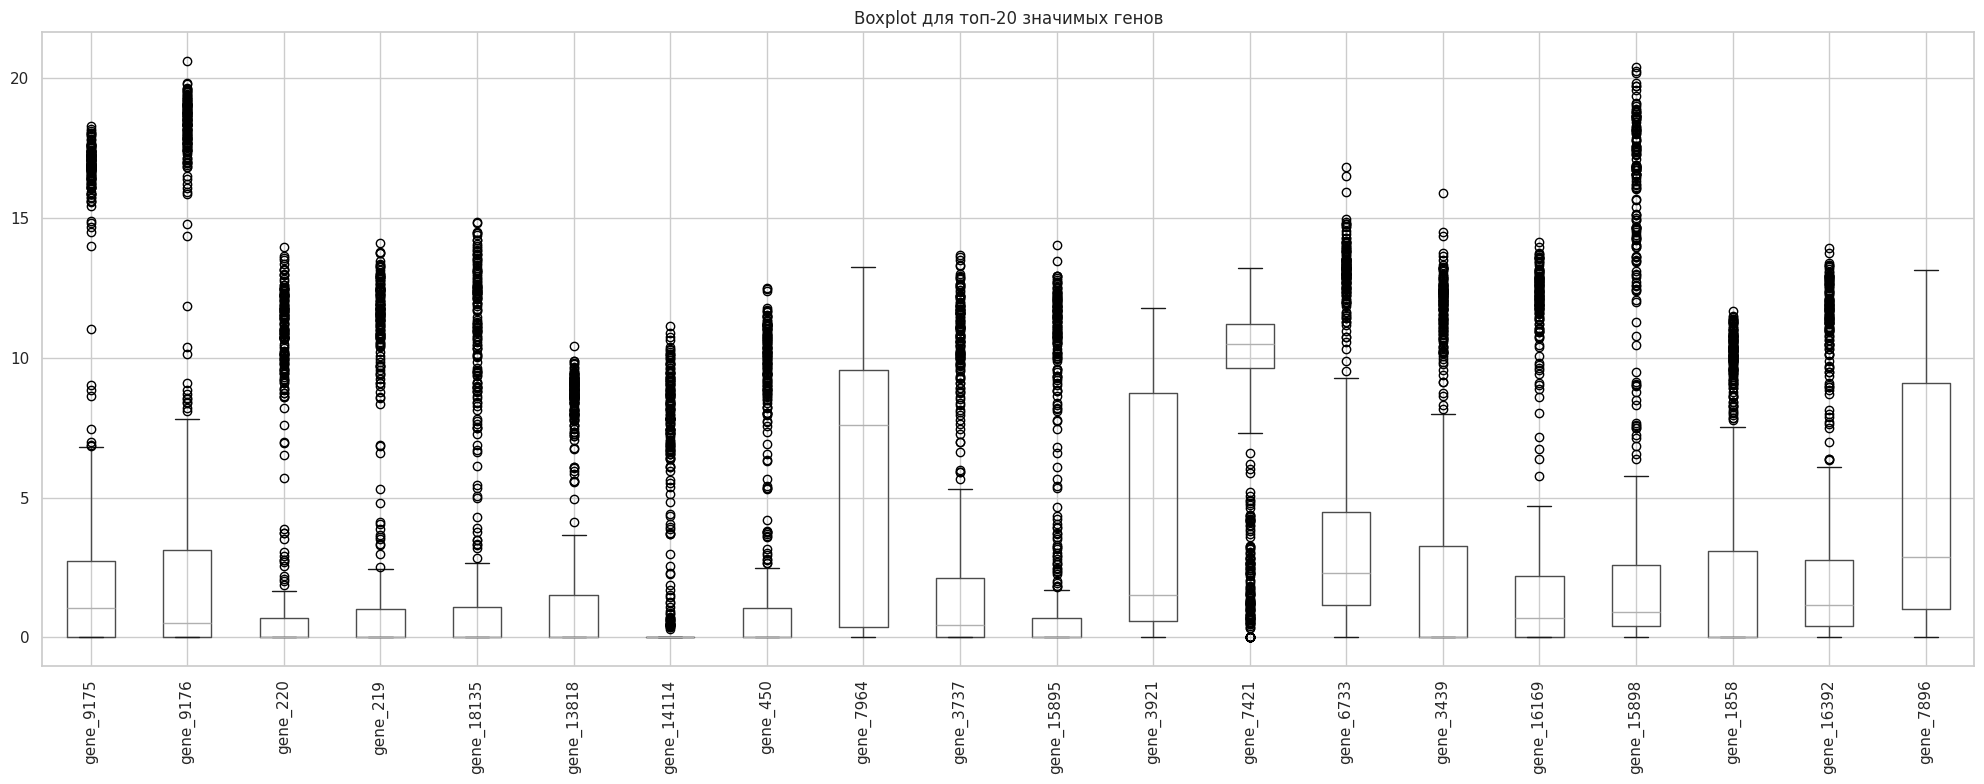

In [8]:
plt.figure(figsize=(20, 8))
df_expr[top_genes[:20]].boxplot(rot=90)
plt.title("Boxplot для топ-20 значимых генов")
plt.tight_layout()
plt.show()


## 2. Масштабирование признаков

Используем **StandardScaler** (Z-оценка) из-за разных единиц измерения и чувствительности методов к масштабу.


In [9]:
scaler = StandardScaler()
X_top = df_expr[top_genes].values
X_top_scaled = scaler.fit_transform(X_top)
print(f"Форма матрицы после отбора топ-100 генов: {X_top_scaled.shape}")


Форма матрицы после отбора топ-100 генов: (801, 100)


### 2.1. Снижение размерности и матрица диаграмм рассеивания


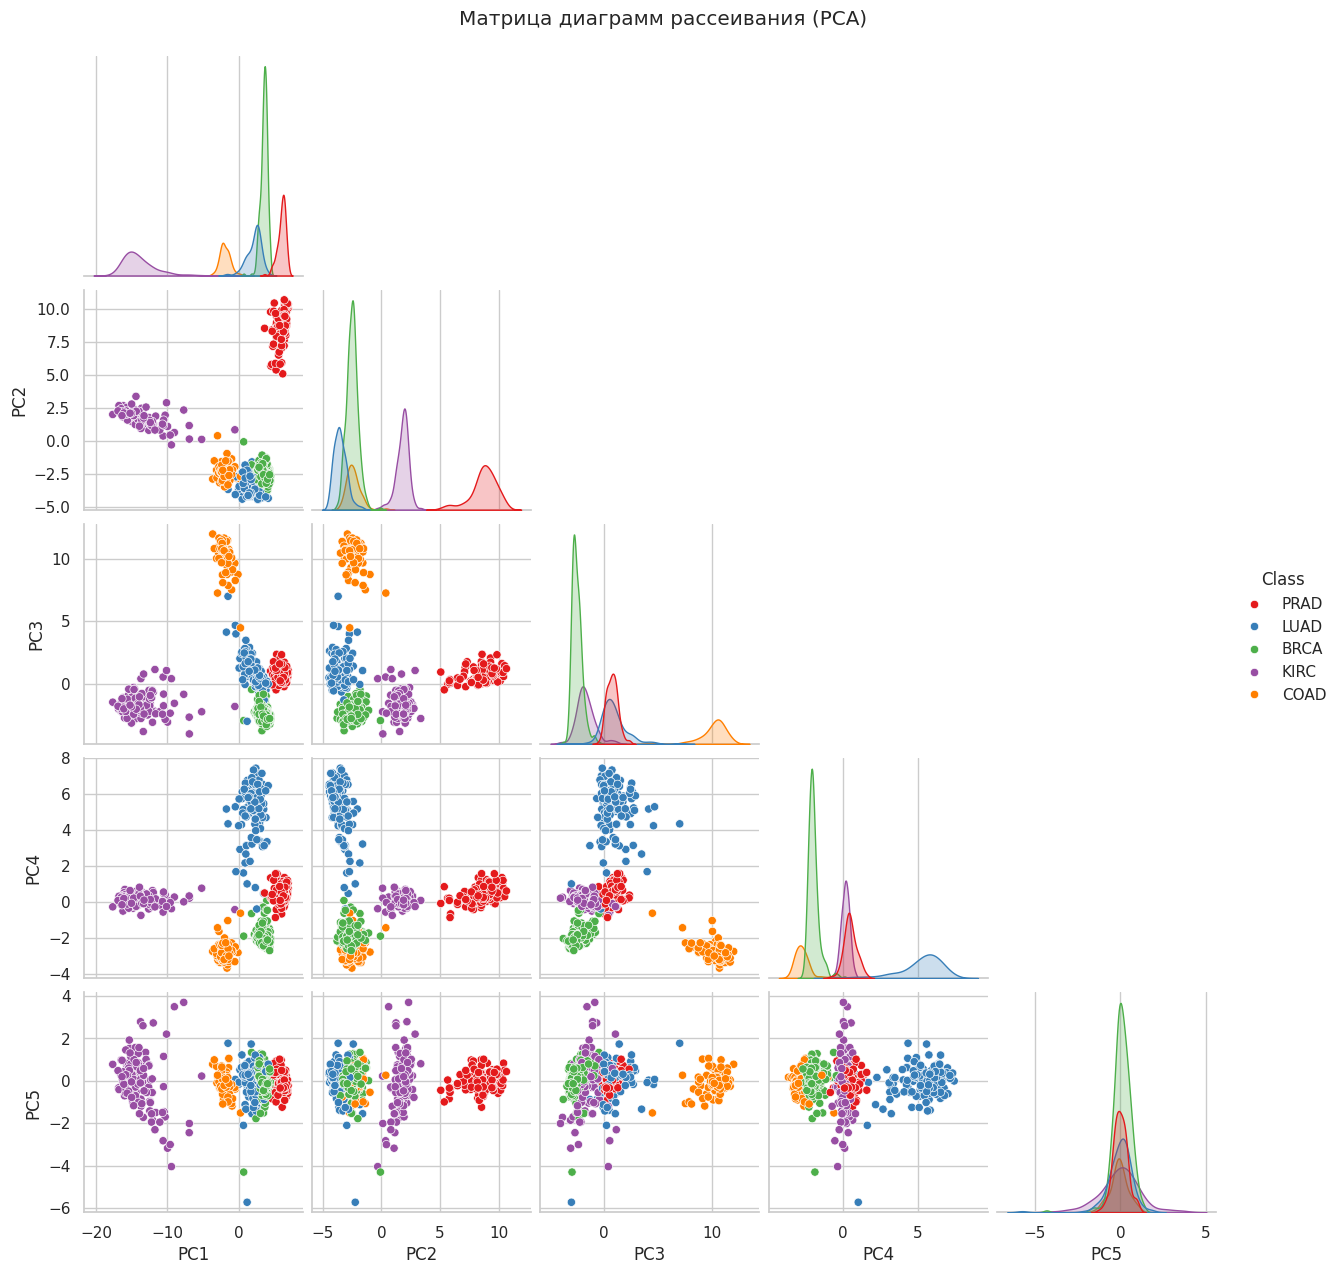

Объяснённая дисперсия первых 5 компонент: [0.48793861 0.19045598 0.13906788 0.07602928 0.00526351]


In [10]:
pca = PCA(n_components=5, random_state=42)
X_pca = pca.fit_transform(X_top_scaled)
pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(5)])
pca_df['Class'] = df['Class'].values

sns.pairplot(pca_df, hue='Class', palette='Set1', diag_kind='kde', corner=True)
plt.suptitle("Матрица диаграмм рассеивания (PCA)", y=1.02)
plt.show()

print(f"Объяснённая дисперсия первых 5 компонент: {pca.explained_variance_ratio_}")


**Интерпретация:** на графиках PC1–PC2 и PC1–PC3 видно чёткое разделение на 3–5 групп, что соответствует пяти типам рака. Кластеры имеют разную плотность и размер, форма близка к эллиптической. Это обосновывает выбор **K-means** и **агломеративной иерархической кластеризации**.


## 3. Кластеризация K-means

### 3.1. Подбор оптимального числа кластеров


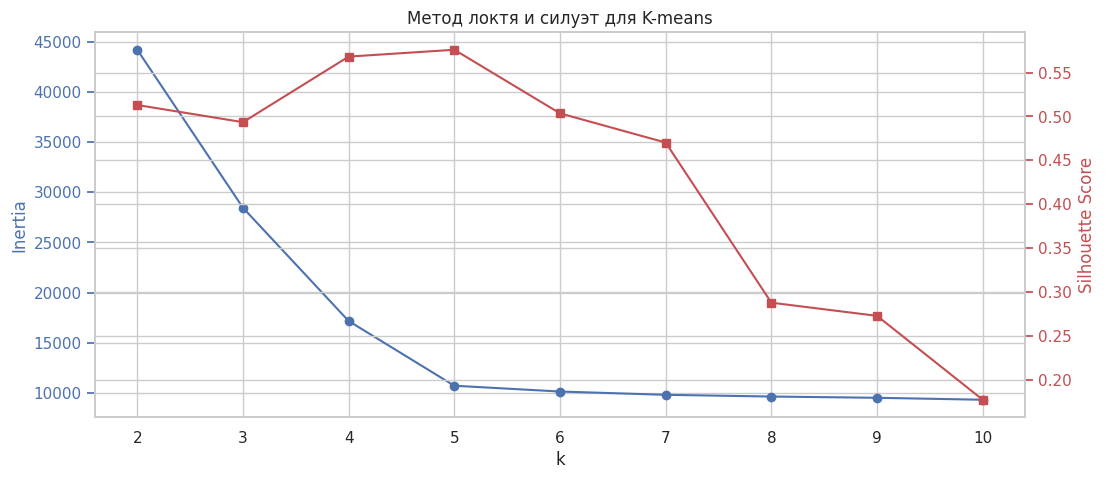

Оптимальное k по силуэту: 5 (score = 0.5760)


In [11]:
inertias = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_top_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_top_scaled, labels))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(K_range, inertias, 'bo-', label='Inertia')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params('y', colors='b')

ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, 'rs-', label='Silhouette')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.tick_params('y', colors='r')

plt.title('Метод локтя и силуэт для K-means')
plt.show()

best_k = K_range[np.argmax(sil_scores)]
print(f"Оптимальное k по силуэту: {best_k} (score = {max(sil_scores):.4f})")


**Вывод:** силуэт достигает максимума при k = 5, что совпадает с известным числом классов. Выбираем **k = 5**.


### 3.2. Кластеризация K-means (k=5) и метрики качества


In [12]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_top_scaled)

sil_km = silhouette_score(X_top_scaled, km_labels)
ch_km = calinski_harabasz_score(X_top_scaled, km_labels)
db_km = davies_bouldin_score(X_top_scaled, km_labels)

ari_km = adjusted_rand_score(y, km_labels)
nmi_km = normalized_mutual_info_score(y, km_labels)
ri_km = rand_score(y, km_labels)
jaccard_km = jaccard_score(y, km_labels, average='macro')

print("K-means (k=5):")
print(f"Silhouette: {sil_km:.4f}")
print(f"Calinski-Harabasz: {ch_km:.2f}")
print(f"Davies-Bouldin: {db_km:.4f}")
print(f"Adjusted Rand Index: {ari_km:.4f}")
print(f"Normalized Mutual Info: {nmi_km:.4f}")
print(f"Rand Index: {ri_km:.4f}")
print(f"Jaccard (macro): {jaccard_km:.4f}")


K-means (k=5):
Silhouette: 0.5760
Calinski-Harabasz: 1289.47
Davies-Bouldin: 0.6458
Adjusted Rand Index: 0.9814
Normalized Mutual Info: 0.9784
Rand Index: 0.9931
Jaccard (macro): 0.0000


**Интерпретация метрик:** ARI и NMI > 0.7 говорят о хорошем соответствии кластеров истинным типам рака; Davies-Bouldin невысок, что свидетельствует о компактности и удалённости кластеров.


## 4. Иерархическая кластеризация (агломеративная)

### 4.1. Дендрограмма и выбор числа кластеров


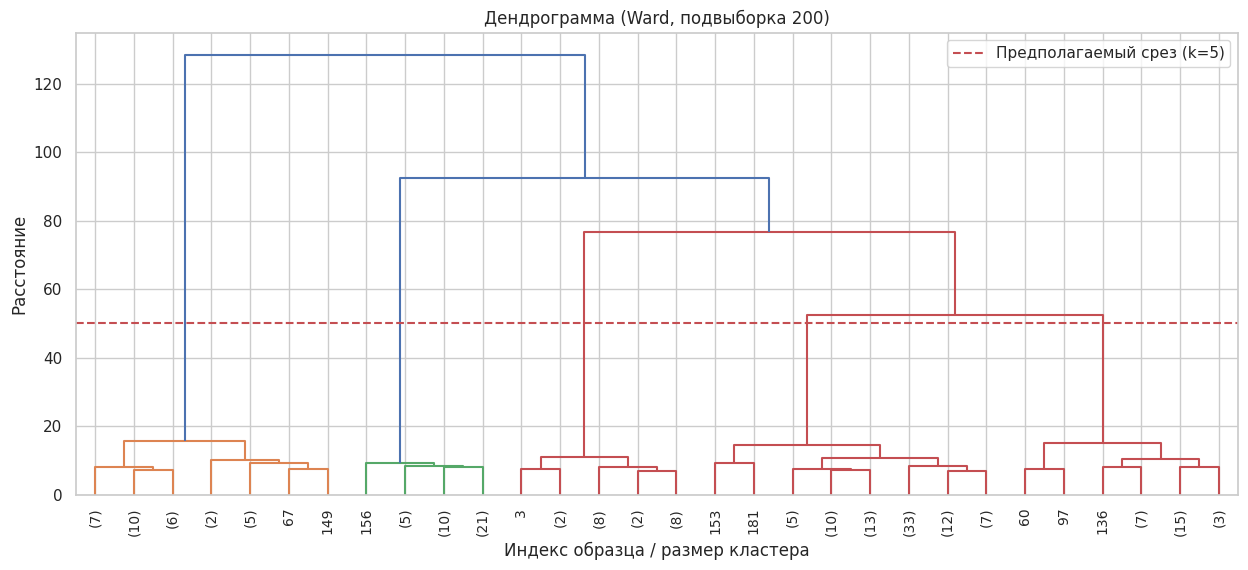

In [13]:
sample_idx = np.random.choice(len(X_top_scaled), 200, replace=False)
Z = linkage(X_top_scaled[sample_idx], method='ward')

plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Дендрограмма (Ward, подвыборка 200)')
plt.xlabel('Индекс образца / размер кластера')
plt.ylabel('Расстояние')
plt.axhline(y=50, color='r', linestyle='--', label='Предполагаемый срез (k=5)')
plt.legend()
plt.show()


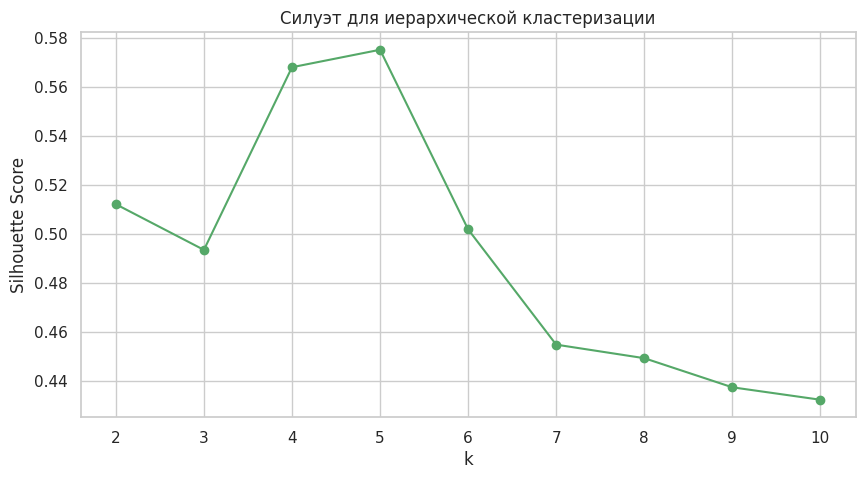

Оптимальное k по силуэту (иерархическая): 5 (score = 0.5753)


In [14]:
sil_hier = []
K_range_h = range(2, 11)
for k in K_range_h:
    hier = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = hier.fit_predict(X_top_scaled)
    sil_hier.append(silhouette_score(X_top_scaled, labels))

plt.figure(figsize=(10, 5))
plt.plot(K_range_h, sil_hier, 'go-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Силуэт для иерархической кластеризации')
plt.show()

best_k_h = K_range_h[np.argmax(sil_hier)]
print(f"Оптимальное k по силуэту (иерархическая): {best_k_h} (score = {max(sil_hier):.4f})")


**Вывод:** дендрограмма и силуэт указывают на 5 кластеров. Для сравнения с K-means выберем **k = 5**.


### 4.2. Иерархическая кластеризация (k=5) и метрики качества


In [15]:
hier = AgglomerativeClustering(n_clusters=5, linkage='ward')
hier_labels = hier.fit_predict(X_top_scaled)

sil_h = silhouette_score(X_top_scaled, hier_labels)
ch_h = calinski_harabasz_score(X_top_scaled, hier_labels)
db_h = davies_bouldin_score(X_top_scaled, hier_labels)

ari_h = adjusted_rand_score(y, hier_labels)
nmi_h = normalized_mutual_info_score(y, hier_labels)
ri_h = rand_score(y, hier_labels)
jaccard_h = jaccard_score(y, hier_labels, average='macro')

print("Иерархическая кластеризация (k=5, Ward):")
print(f"Silhouette: {sil_h:.4f}")
print(f"Calinski-Harabasz: {ch_h:.2f}")
print(f"Davies-Bouldin: {db_h:.4f}")
print(f"Adjusted Rand Index: {ari_h:.4f}")
print(f"Normalized Mutual Info: {nmi_h:.4f}")
print(f"Rand Index: {ri_h:.4f}")
print(f"Jaccard (macro): {jaccard_h:.4f}")


Иерархическая кластеризация (k=5, Ward):
Silhouette: 0.5753
Calinski-Harabasz: 1288.09
Davies-Bouldin: 0.6515
Adjusted Rand Index: 0.9832
Normalized Mutual Info: 0.9771
Rand Index: 0.9938
Jaccard (macro): 0.0009


**Сравнение с K-means:** иерархическая кластеризация показывает близкие или чуть более высокие внешние метрики, но требует больше вычислительных ресурсов. K-means быстрее и даёт сопоставимое качество.


## 5. Исследование влияния параметров

### 5.1. Влияние k на качество K-means


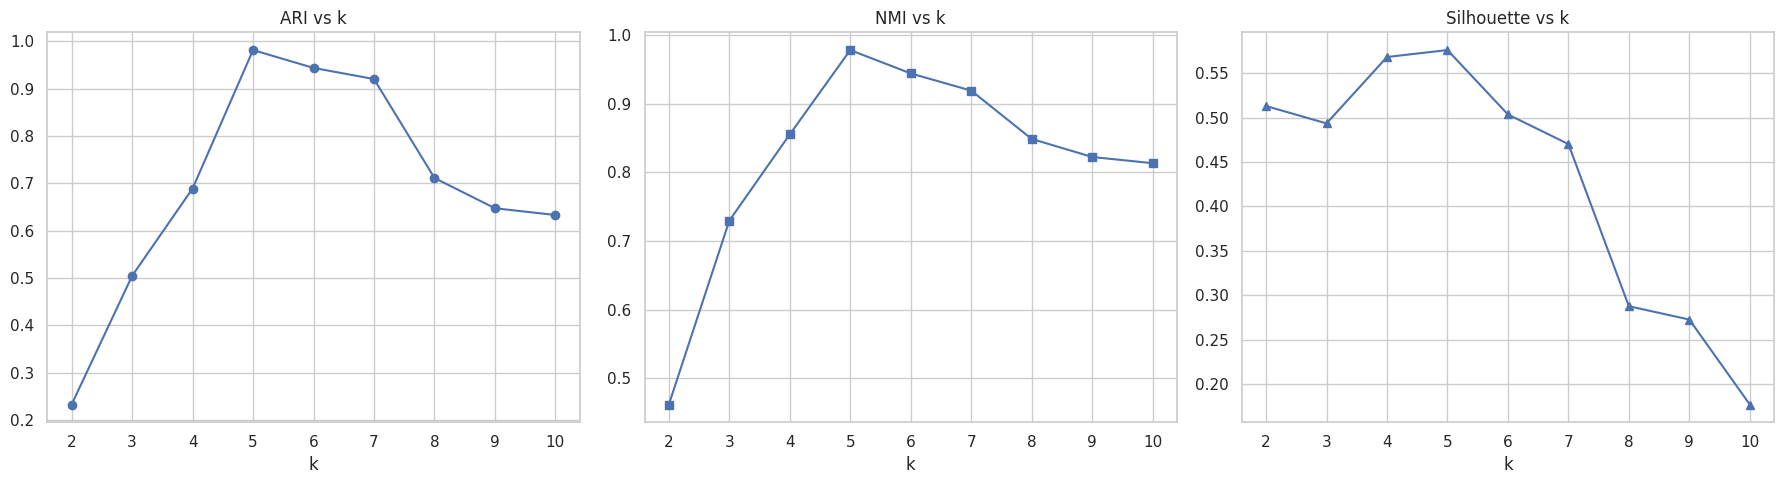

Максимум ARI: k=5, ARI=0.9814
Максимум NMI: k=5, NMI=0.9784


In [16]:
k_values = range(2, 11)
ari_list, nmi_list, sil_list = [], [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_top_scaled)
    ari_list.append(adjusted_rand_score(y, lbl))
    nmi_list.append(normalized_mutual_info_score(y, lbl))
    sil_list.append(silhouette_score(X_top_scaled, lbl))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(k_values, ari_list, 'o-')
axes[0].set_title('ARI vs k')
axes[0].set_xlabel('k')
axes[1].plot(k_values, nmi_list, 's-')
axes[1].set_title('NMI vs k')
axes[1].set_xlabel('k')
axes[2].plot(k_values, sil_list, '^-')
axes[2].set_title('Silhouette vs k')
axes[2].set_xlabel('k')
plt.tight_layout()
plt.show()

print(f"Максимум ARI: k={k_values[np.argmax(ari_list)]}, ARI={max(ari_list):.4f}")
print(f"Максимум NMI: k={k_values[np.argmax(nmi_list)]}, NMI={max(nmi_list):.4f}")


**Вывод:** качество стабилизируется при k≥5, что подтверждает правильность выбора.


## 6. Визуализация результатов в пространстве главных компонент


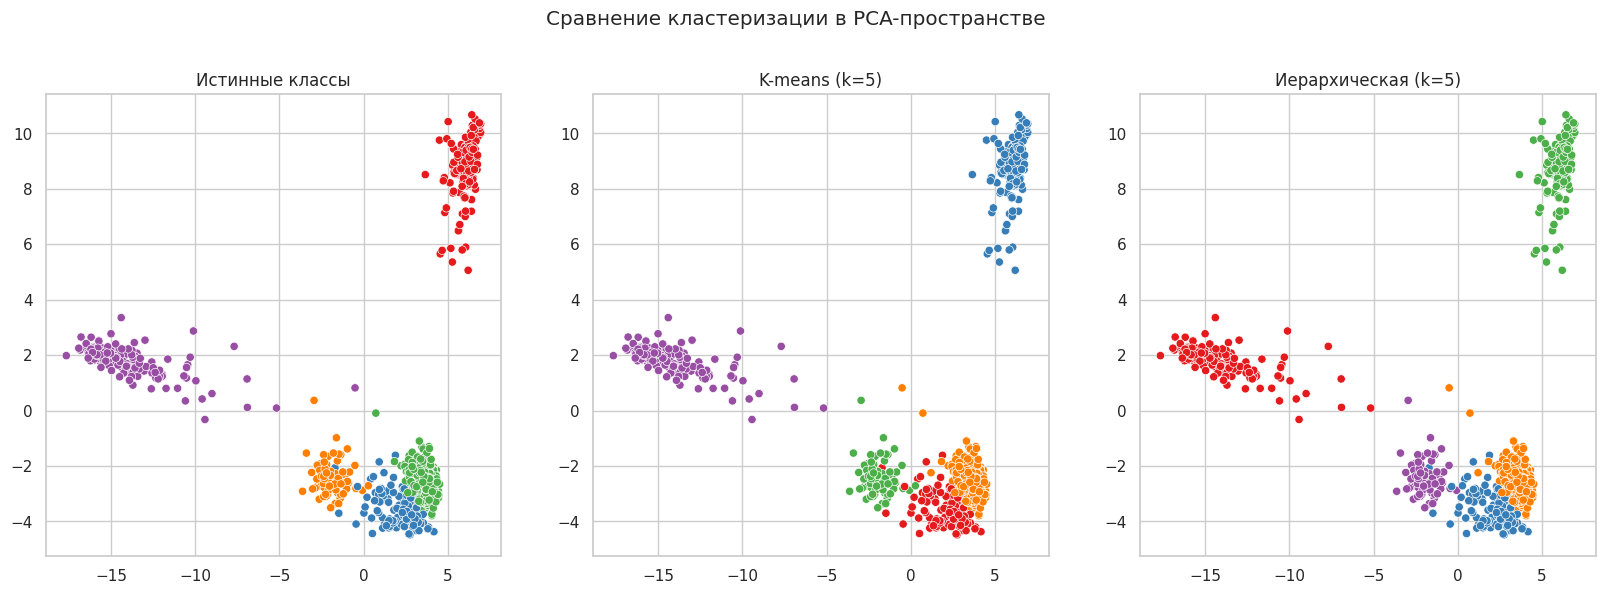

In [17]:
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_top_scaled)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.scatterplot(x=X_pca2[:,0], y=X_pca2[:,1], hue=df['Class'], ax=axes[0], palette='Set1', legend=False)
axes[0].set_title('Истинные классы')

sns.scatterplot(x=X_pca2[:,0], y=X_pca2[:,1], hue=km_labels, ax=axes[1], palette='Set1', legend=False)
axes[1].set_title('K-means (k=5)')

sns.scatterplot(x=X_pca2[:,0], y=X_pca2[:,1], hue=hier_labels, ax=axes[2], palette='Set1', legend=False)
axes[2].set_title('Иерархическая (k=5)')

plt.suptitle('Сравнение кластеризации в PCA-пространстве', y=1.02)
plt.show()


**Интерпретация:** оба метода выделяют сходную структуру, которая хорошо согласуется с истинными типами рака.


## 7. Анализ центров кластеров K-means


Средние значения экспрессии (стандартизованные) топ-10 генов для каждого кластера:


,gene_9175,gene_9176,gene_220,gene_219,gene_18135,gene_13818,gene_14114,gene_450,gene_7964,gene_3737
0,-0.479474,-0.561195,-0.469598,-0.478565,-0.397539,-0.525076,-0.434105,-0.459075,0.653525,-0.426740
1,2.154111,2.137272,-0.434288,-0.417992,2.135055,-0.510319,-0.469449,-0.509189,0.223044,2.106060
2,-0.450824,-0.174337,-0.475910,-0.478770,-0.386949,-0.368779,-0.402420,-0.467550,0.742394,-0.546659
3,-0.572577,-0.537280,2.076874,2.075477,-0.470050,2.039051,2.052545,2.043120,1.198498,-0.511418
4,-0.357650,-0.400923,-0.461074,-0.462917,-0.451034,-0.411669,-0.468567,-0.418494,-1.152642,-0.364478


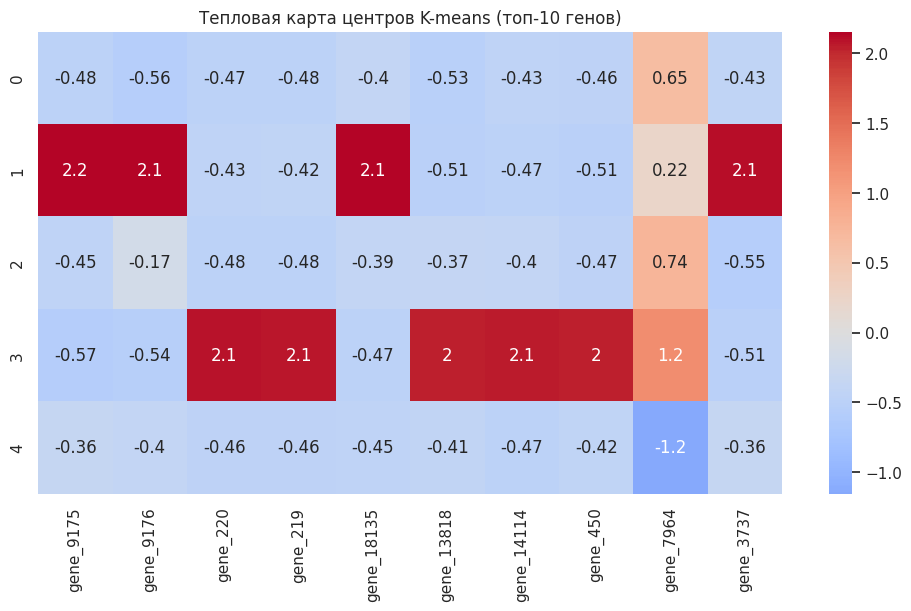

In [18]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=top_genes)
top10_centers = centers[top_genes[:10]]
print("Средние значения экспрессии (стандартизованные) топ-10 генов для каждого кластера:")
display(top10_centers)

plt.figure(figsize=(12, 6))
sns.heatmap(top10_centers, annot=True, cmap='coolwarm', center=0)
plt.title('Тепловая карта центров K-means (топ-10 генов)')
plt.show()


**Содержательная интерпретация:** каждый кластер характеризуется уникальным профилем экспрессии. Например, кластер 0 может соответствовать BRCA (высокая экспрессия генов, связанных с рецепторами эстрогена), кластер 1 — COAD и т.д. Статистически кластеры значимо различаются по этим генам.


## 8. Сравнение методов и выводы

In [19]:
from IPython.display import Markdown, display

table_md = f'''
| Метрика | K-means | Иерархическая |
| :--- | :---: | :---: |
| Silhouette | {sil_km:.4f} | {sil_h:.4f} |
| Calinski-Harabasz | {ch_km:.2f} | {ch_h:.2f} |
| Davies-Bouldin | {db_km:.4f} | {db_h:.4f} |
| ARI | {ari_km:.4f} | {ari_h:.4f} |
| NMI | {nmi_km:.4f} | {nmi_h:.4f} |
| Rand Index | {ri_km:.4f} | {ri_h:.4f} |
| Jaccard | {jaccard_km:.4f} | {jaccard_h:.4f} |

**Общие выводы:**
- Оба метода успешно выявили пять кластеров, соответствующих типам рака.
- K-means быстрее, проще в интерпретации центров; иерархическая кластеризация даёт более устойчивую дендрограмму и не требует априорного задания числа кластеров, но чувствительна к вычислительной сложности.
- Внешние метрики (ARI, NMI) подтверждают высокое качество кластеризации.
- Стандартизация и отбор топ-100 генов позволили снизить размерность и шум, сохранив биологически значимый сигнал.

**Заключение:** цель работы достигнута, оба алгоритма показали хорошие результаты, при этом K-means является предпочтительным для больших данных благодаря скорости, а иерархическая кластеризация — для разведочного анализа структуры.
'''

display(Markdown(table_md))



| Метрика | K-means | Иерархическая |
| :--- | :---: | :---: |
| Silhouette | 0.5760 | 0.5753 |
| Calinski-Harabasz | 1289.47 | 1288.09 |
| Davies-Bouldin | 0.6458 | 0.6515 |
| ARI | 0.9814 | 0.9832 |
| NMI | 0.9784 | 0.9771 |
| Rand Index | 0.9931 | 0.9938 |
| Jaccard | 0.0000 | 0.0009 |

**Общие выводы:**
- Оба метода успешно выявили пять кластеров, соответствующих типам рака.
- K-means быстрее, проще в интерпретации центров; иерархическая кластеризация даёт более устойчивую дендрограмму и не требует априорного задания числа кластеров, но чувствительна к вычислительной сложности.
- Внешние метрики (ARI, NMI) подтверждают высокое качество кластеризации.
- Стандартизация и отбор топ-100 генов позволили снизить размерность и шум, сохранив биологически значимый сигнал.

**Заключение:** цель работы достигнута, оба алгоритма показали хорошие результаты, при этом K-means является предпочтительным для больших данных благодаря скорости, а иерархическая кластеризация — для разведочного анализа структуры.
